In [1]:
#Importing the dataset
import pandas as pd
import numpy as np


reg_path= "../../data/Regression_datasets/adtech.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

   clicks  session_time  cart_adds     revenue
0      34      8.247081          2  321.174533
1      51      7.482857          3  388.433480
2      58      8.766434          4  470.364412
3      50     10.851948          6  599.150770
4      51      8.997615          6  600.518679


##Lets do some feaature engineering

In [2]:
#informations
print(reg_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   clicks        10000 non-null  int64  
 1   session_time  10000 non-null  float64
 2   cart_adds     10000 non-null  int64  
 3   revenue       10000 non-null  float64
dtypes: float64(2), int64(2)
memory usage: 312.6 KB
None


from info  we find no null values all are int and flot type and 10000 data. Lets describe in next step

In [3]:
print(reg_data.describe())

             clicks  session_time     cart_adds       revenue
count  10000.000000  10000.000000  10000.000000  10000.000000
mean      49.930600      9.965053      4.994000    549.397918
std        7.065081      2.985103      2.246524    130.438381
min       26.000000     -1.244130      0.000000    152.067554
25%       45.000000      7.937888      3.000000    458.737857
50%       50.000000      9.953982      5.000000    544.836078
75%       55.000000     11.997046      6.000000    632.406460
max       77.000000     21.504768     16.000000   1131.812829


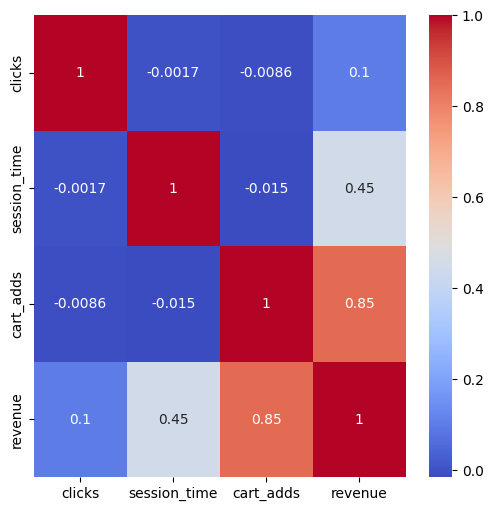

In [4]:
#correlation with heatmap
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 6))
sns.heatmap(reg_data.corr(), annot=True, cmap='coolwarm')
plt.show()

based on correlation we found cart_add and revenue ara 85% corelated
sessiontime and revenue are 45% corelated
clicks and revenue are 10% correlated

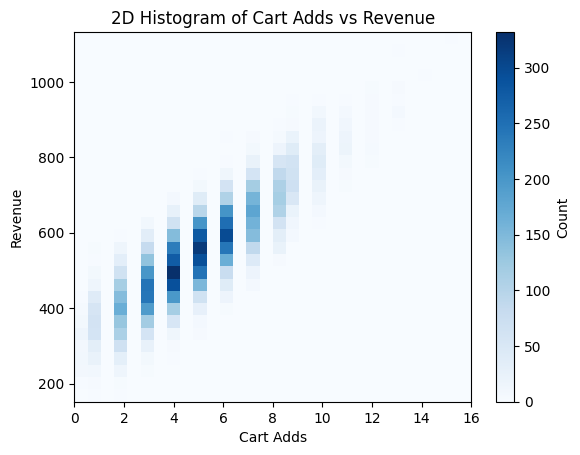

In [5]:
plt.hist2d(reg_data['cart_adds'], reg_data['revenue'], bins=30, cmap='Blues')
plt.colorbar(label='Count')
plt.xlabel('Cart Adds')
plt.ylabel('Revenue')
plt.title('2D Histogram of Cart Adds vs Revenue')
plt.show()

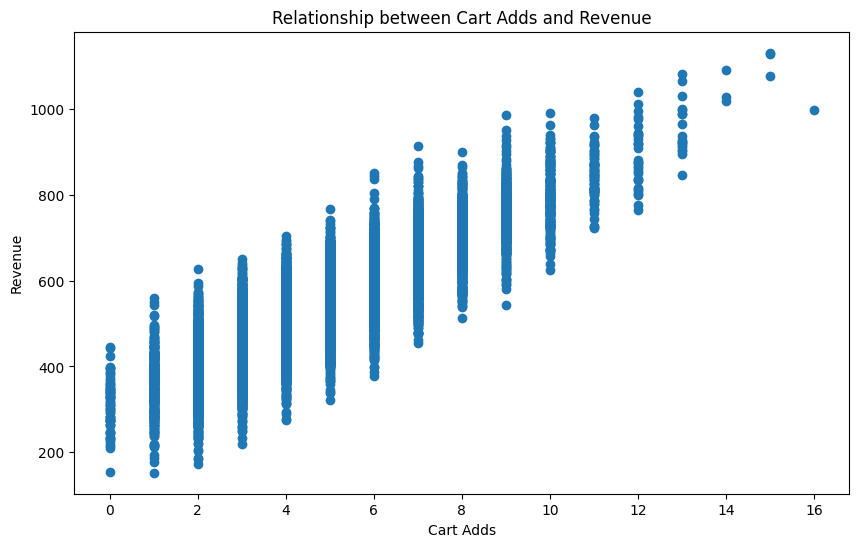

In [6]:
#scatter plot of revenue vs cart_adds
plt.figure(figsize=(10, 6))
plt.scatter(reg_data['cart_adds'], reg_data['revenue'])
plt.xlabel('Cart Adds')
plt.ylabel('Revenue')
plt.title('Relationship between Cart Adds and Revenue')
plt.show()

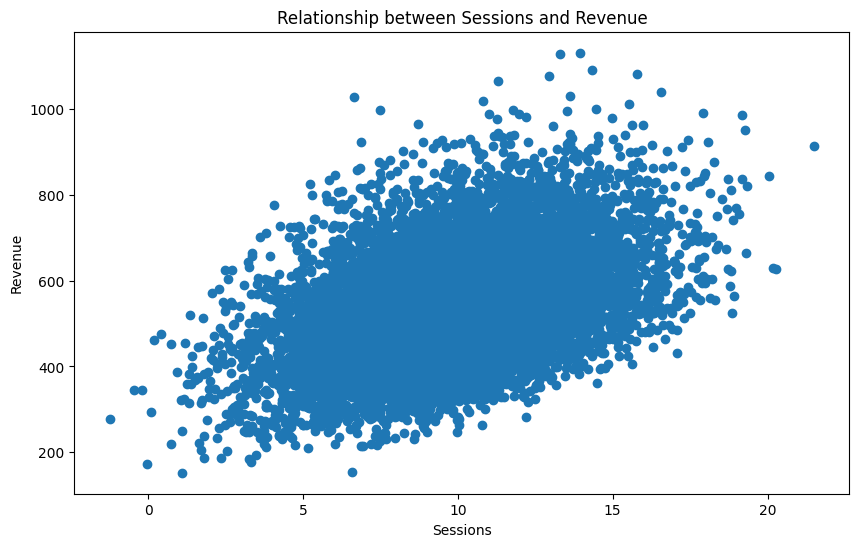

In [7]:
#scatter plot of revenue vs cart_adds
plt.figure(figsize=(10, 6))
plt.scatter(reg_data['session_time'], reg_data['revenue'])
plt.xlabel('Sessions')
plt.ylabel('Revenue')
plt.title('Relationship between Sessions and Revenue')
plt.show()

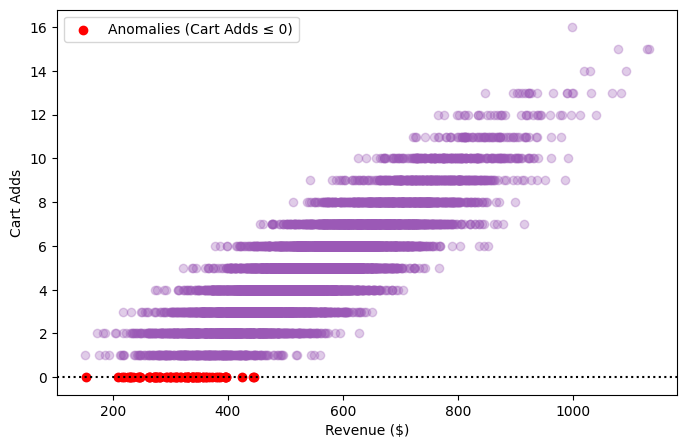

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(reg_data['revenue'], reg_data['cart_adds'], alpha=0.3, color='#9b59b6')

# Highlight specific anomalies (e.g., impossible negative demand)
anomalies = reg_data[reg_data['cart_adds'] <= 0]
plt.scatter(
    anomalies['revenue'],
    anomalies['cart_adds'],
    color='red',
    label='Anomalies (Cart Adds ≤ 0)',
)
plt.axhline(0, color='black', linestyle=':')
plt.xlabel('Revenue ($)')
plt.ylabel('Cart Adds')
plt.legend()
plt.show()

#Cart is zero still getting revenue

In [9]:
#linear regression model with all features
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X = reg_data[['cart_adds', 'session_time']]
y = reg_data['revenue']

linear_model = LinearRegression()
linear_model.fit(X, y)

X_train_revenue, X_test_revenue, y_train_revenue, y_test_revenue = train_test_split(
    X, y, test_size=0.20, random_state=42)

y_pred_revenue = linear_model.predict(X_test_revenue)
mse_revenue = mean_squared_error(y_test_revenue, y_pred_revenue)
r2_revenue = r2_score(y_test_revenue, y_pred_revenue)
print(f"Mean Squared Error (MSE): {mse_revenue}")
print(f"R-squared (R2): {r2_revenue}")

Mean Squared Error (MSE): 1099.2909650246897
R-squared (R2): 0.9340997389291438


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [10]:
#let filter outlier that cart adds is less than 0
reg_data_cart = reg_data[reg_data['cart_adds'] > 0]    

X = reg_data_cart[['cart_adds', 'session_time']]
y = reg_data_cart['revenue']

linear_model = LinearRegression()
linear_model.fit(X, y)

X_train_revenue, X_test_revenue, y_train_revenue, y_test_revenue = train_test_split(
    X, y, test_size=0.20, random_state=42)

y_pred_revenue = linear_model.predict(X_test_revenue)
mse_revenue = mean_squared_error(y_test_revenue, y_pred_revenue)
r2_revenue = r2_score(y_test_revenue, y_pred_revenue)
print(f"Mean Squared Error (MSE): {mse_revenue}")
print(f"R-squared (R2): {r2_revenue}")

Mean Squared Error (MSE): 1120.9097155480176
R-squared (R2): 0.9367808279840009


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [11]:
reg_data_cart.shape

(9932, 4)

In [12]:
#let add click column to the dataset
x= X = reg_data_cart.drop(columns=['revenue'],axis=1)
y= reg_data_cart['revenue']

linear_model = LinearRegression()
linear_model.fit(X, y)

X_train_revenue, X_test_revenue, y_train_revenue, y_test_revenue = train_test_split(
    X, y, test_size=0.20, random_state=42)

y_pred_revenue = linear_model.predict(X_test_revenue)
mse_revenue = mean_squared_error(y_test_revenue, y_pred_revenue)
r2_revenue = r2_score(y_test_revenue, y_pred_revenue)
print(f"Mean Squared Error (MSE): {mse_revenue}")
print(f"R-squared (R2): {round(r2_revenue, 2)}")

Mean Squared Error (MSE): 935.1967696046731
R-squared (R2): 0.95


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


Almost 95% prediction accuracy is done.

In [13]:
#do k-fold cross validation
from sklearn.model_selection import cross_val_score 

cross_val_scores = cross_val_score(linear_model, X, y, cv=5, scoring='r2')
print(f"Cross-validated R-squared (R2): {round(cross_val_scores.mean(), 2)}")

Cross-validated R-squared (R2): 0.95


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

after cross_validation also getting prediction score 95% that means data distributed equally.

/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i


--- Model Performance Comparison ---
                  Model Best Alpha  Train RMSE  Test RMSE  Test MAE  Test R²
Linear Regression (OLS)        N/A       30.14      30.59     24.53   0.9472
       Ridge Regression     0.7565       30.14      30.59     24.53   0.9472
       Lasso Regression     0.0028       30.14      30.59     24.53   0.9472
  ElasticNet Regression     0.0005       30.14      30.59     24.53   0.9472

🏆 **Best Suited Model:** Linear Regression (OLS)

--- Feature Coefficients (Linear Regression (OLS)) ---
     Feature  Coefficient
   cart_adds   109.228697
session_time    60.088779
      clicks    14.198662


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

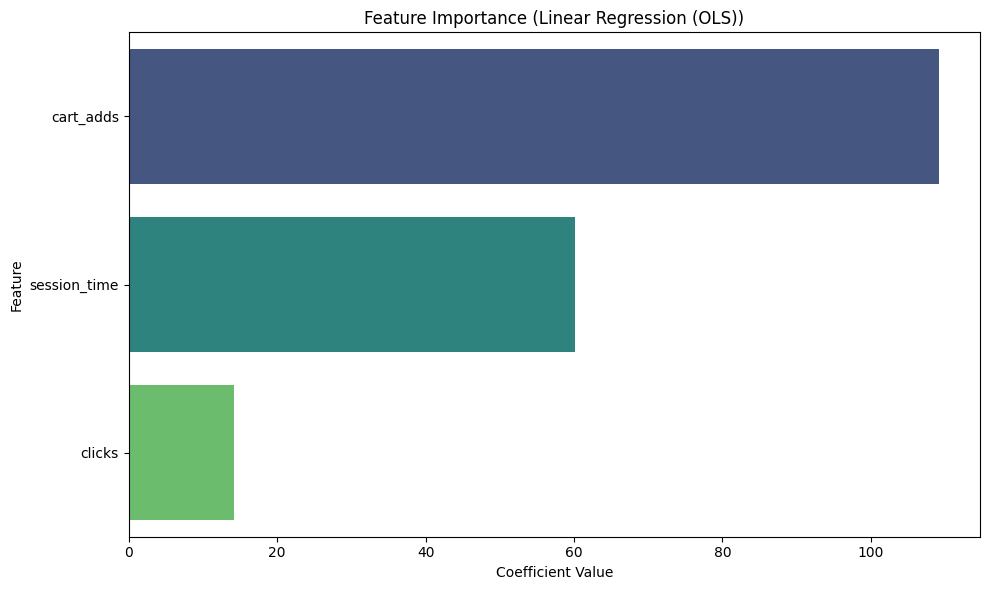

In [14]:
import data_utils as du
du.find_bestmodel(X,y)